In [11]:
import numpy as np
from pathlib import Path
import re
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from scipy.special import erf

c0 = 299792458
h = 6.62606957 * (10 ** -34)
e = 1.602176565 * (10 ** -19)

In [12]:
def Elliott(x, A, B, E_G, E_B, sigma):
    #Exiton bit
    first_bit = A/ x

    whole_summation_term = np.zeros_like(x, dtype=float)
    for n in range(1, 10):
        #dirac delta funciton
        prefactor = 1/(np.sqrt(2*np.pi*sigma**2))
        centre = E_G - (E_B/(n**2))
        exponential = np.exp(-((x-centre)**2)/(2*sigma**2))
        dirac_delta = prefactor * exponential

        #other elliot equation inside of the sumamtion
        summation_bit_pre_dirac_delta = (4* np.pi * (E_B**(3/2)))/(n**3)
        summation_term = summation_bit_pre_dirac_delta * dirac_delta

        whole_summation_term += summation_term
    Exiton_bit = whole_summation_term * first_bit

    #general bit
    first_bit = B/ np.where(x == 0, np.inf, x)

        #delta = np.maximum(x - E_G, 1e-6)
    delta = x-E_G
    bit_pre_JDoS = np.zeros_like(x)
    safe = delta > 0
    wierd_bit = 2*np.pi * np.sqrt(E_B/delta)
    wierd_bit = 2 * np.pi * np.sqrt(E_B/(delta[safe]))
    bit_pre_JDoS[safe] = wierd_bit / (1-np.exp(-wierd_bit))

        #JDoS bit
    JDoS = np.zeros_like(x)
    JDoS[safe] = np.sqrt(delta[safe])
    JDoS_term = JDoS * bit_pre_JDoS

    General_bit = first_bit * JDoS_term
    return (General_bit + Exiton_bit)

def the_exiton_bit(x, A, E_G, E_B, sigma):
    first_bit = A/ x

    whole_summation_term = np.zeros_like(x, dtype=float)
    for n in range(1, 10):
        #dirac delta funciton
        prefactor = 1/(np.sqrt(2*np.pi*sigma**2))
        centre = E_G - (E_B/(n**2))
        exponential = np.exp(-((x-centre)**2)/(2*sigma**2))
        dirac_delta = prefactor * exponential

        #other elliot equation inside of the sumamtion
        summation_bit_pre_dirac_delta = (4* np.pi * (E_B**(3/2)))/(n**3)
        summation_term = summation_bit_pre_dirac_delta * dirac_delta

        whole_summation_term += summation_term
    return whole_summation_term * first_bit

def general_bit(x, A, E_G, E_B):
    first_bit = A/ np.where(x == 0, np.inf, x)
    #first_bit = A

    #delta = np.maximum(x - E_G, 1e-6)
    delta = x-E_G
    bit_pre_JDoS = np.zeros_like(x)
    safe = delta > 0
    wierd_bit = 2*np.pi * np.sqrt(E_B/delta)
    wierd_bit = 2 * np.pi * np.sqrt(E_B/(delta[safe]))
    bit_pre_JDoS[safe] = wierd_bit / (1-np.exp(-wierd_bit))

    #JDoS bit
    JDoS = np.zeros_like(x)
    JDoS[safe] = np.sqrt(delta[safe])
    JDoS_term = JDoS * bit_pre_JDoS
    #JDoS_term = JDoS * bit_pre_JDoS/(1-test*(x-E_G))
    return first_bit * JDoS_term

In [13]:
def Elliott(x, A, E_G, E_B, sigma):
  # Exciton bit
  first_bit = A / np.where(x == 0, np.inf, x)

  whole_summation_term = np.zeros_like(x, dtype=float)
  for n in range(1, 10):
    # dirac delta function (Gaussian broadened)
    prefactor = 1 / (np.sqrt(2 * np.pi * sigma**2))
    centre = E_G - (E_B / (n**2))
    exponential = np.exp(-((x - centre) ** 2) / (2 * sigma**2))
    dirac_delta = prefactor * exponential

    # other elliott equation inside of the summation
    summation_bit_pre_dirac_delta = (4 * np.pi * (E_B ** (3 / 2))) / (n**3)
    summation_term = summation_bit_pre_dirac_delta * dirac_delta

    whole_summation_term += summation_term
  Exiton_bit = whole_summation_term * first_bit

  # General bit (uses same A so continuum cannot drop to zero independently)
  delta = x - E_G

  # Smoothly broaden the step at E_G using sigma instead of hard delta > 0 cutoff
  broadened_step = 0.5 * (1.0 + erf(delta / (np.sqrt(2.0) * sigma)))
  smooth_delta = np.sqrt(delta**2 + (0.5 * sigma) ** 2)

  wierd_bit = 2 * np.pi * np.sqrt(E_B / smooth_delta)
  bit_pre_JDoS = wierd_bit / (1 - np.exp(-wierd_bit))

  # JDoS bit
  JDoS = np.sqrt(smooth_delta) * broadened_step
  JDoS_term = JDoS * bit_pre_JDoS

  General_bit = first_bit * JDoS_term
  return General_bit + Exiton_bit


def the_exiton_bit(x, A, E_G, E_B, sigma):
  first_bit = A / np.where(x == 0, np.inf, x)

  whole_summation_term = np.zeros_like(x, dtype=float)
  for n in range(1, 10):
    prefactor = 1 / (np.sqrt(2 * np.pi * sigma**2))
    centre = E_G - (E_B / (n**2))
    exponential = np.exp(-((x - centre) ** 2) / (2 * sigma**2))
    dirac_delta = prefactor * exponential

    summation_bit_pre_dirac_delta = (4 * np.pi * (E_B ** (3 / 2))) / (n**3)
    summation_term = summation_bit_pre_dirac_delta * dirac_delta

    whole_summation_term += summation_term
  return whole_summation_term * first_bit


def general_bit(x, A, E_G, E_B, sigma):
  first_bit = A / np.where(x == 0, np.inf, x)
  delta = x - E_G

  broadened_step = 0.5 * (1.0 + erf(delta / (np.sqrt(2.0) * sigma)))
  smooth_delta = np.sqrt(delta**2 + (0.5 * sigma) ** 2)

  wierd_bit = 2 * np.pi * np.sqrt(E_B / smooth_delta)
  bit_pre_JDoS = wierd_bit / (1 - np.exp(-wierd_bit))

  JDoS = np.sqrt(smooth_delta) * broadened_step
  JDoS_term = JDoS * bit_pre_JDoS
  return first_bit * JDoS_term

In [14]:
dictionary = {}
directory = Path(f"D:\\University\\code\\UV-Vis Data\\Second_set")
naming_system = re.compile(fr"(.+).0.dpt")
for file in directory.glob("*.0.dpt"):
    name = naming_system.match(file.name).group(1)
    # Read tab-separated values directly with no header
    df = pd.read_csv(file, sep="\t", header=None, names=["wavenumber", "absorption"], dtype=float)
    dictionary[name] = df

dictionary_plot = {}
for key, df in dictionary.items():
    # Direct unit conversion: E (eV) = h * c * wavenumber (in m^-1) / e
    wavenumber_m = df["wavenumber"].to_numpy() * 100.0
    x_eV = (h * c0 * wavenumber_m) / e
    y_abs = df["absorption"].to_numpy()
    
    # Sort by energy ascending (wavenumbers are often saved high-to-low)
    sort_idx = np.argsort(x_eV)
    dictionary_plot[f"{key}_x"] = x_eV[sort_idx]
    dictionary_plot[f"{key}_y"] = y_abs[sort_idx]
#for key, df in dictionary.items():
#    print(key)
#    x_cm_minus1_list = []
#    y_list = []
#    for i in dictionary[f"{key}"]:
#        x_cm_minus1, y = zip(*(item.split("\t") for item in dictionary[f"{key}"][i]))
#        x_cm_minus1_list.append(x_cm_minus1)
#        y_list.append(float(y))
#    print(len(x_cm_minus1))
#    x_cm = []
#    for i in x_cm_minus1:
#        x_cm.append(float(1)/float(i))
#    x_m = np.array(x_cm) / 100
#    #x_nm = x_m * (10 ** 9)
#    x_J = h * c0 / x_m
#    x_eV = x_J / e
#
#    dictionary_plot.update({f"{key}_x": x_eV, f"{key}_y":np.array(y)})
#print(dictionary_plot.keys())

C:\Users\msp26rmr\AppData\Local\Temp\ipykernel_19592\1560368925.py:14: RuntimeWarning: invalid value encountered in scalar power
  summation_bit_pre_dirac_delta = (4 * np.pi * (E_B ** (3 / 2))) / (n**3)
C:\Users\msp26rmr\AppData\Local\Temp\ipykernel_19592\1560368925.py:27: RuntimeWarning: invalid value encountered in sqrt
  wierd_bit = 2 * np.pi * np.sqrt(E_B / smooth_delta)


1.7694543862906038 1.8215094019148967 0.011375967409456077 0.028144329154652953


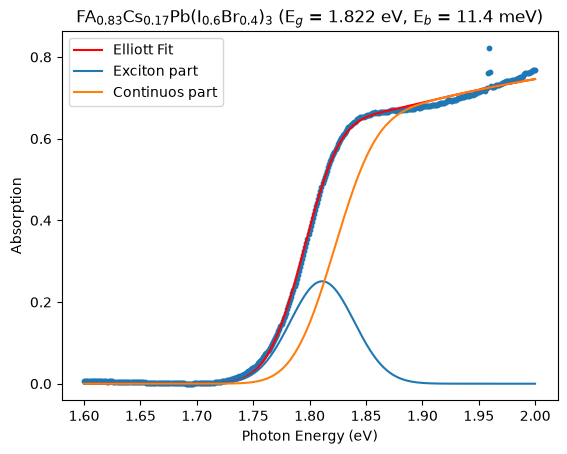

1.7711858728833403 1.822943036686008 0.011362054314756844 0.027180139844828147


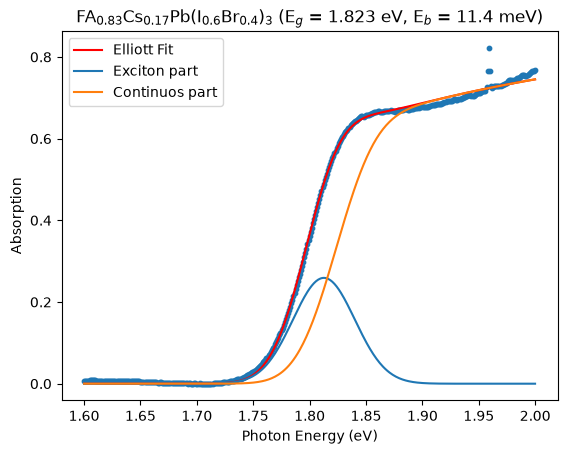

1.804623822087979 1.8204009933207361 0.010985308560040529 0.028137876825432808


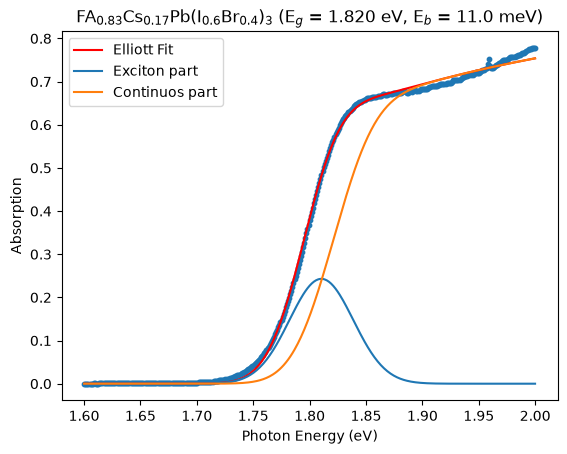

1.7980322576432826 1.8212264220765495 0.011778775948008077 0.02921832265674858


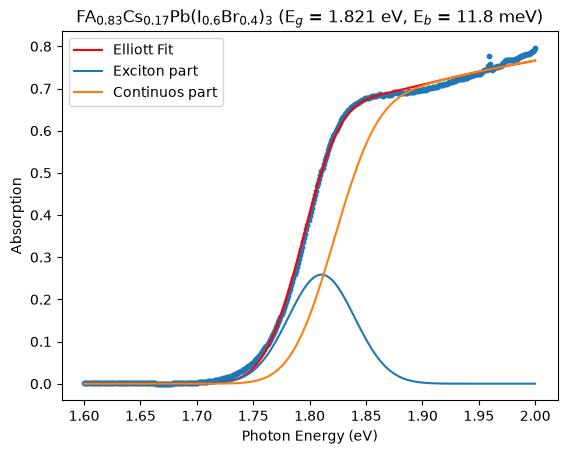

1.8079842536421578 1.8203195353081414 0.01090769236255445 0.027037206469484924


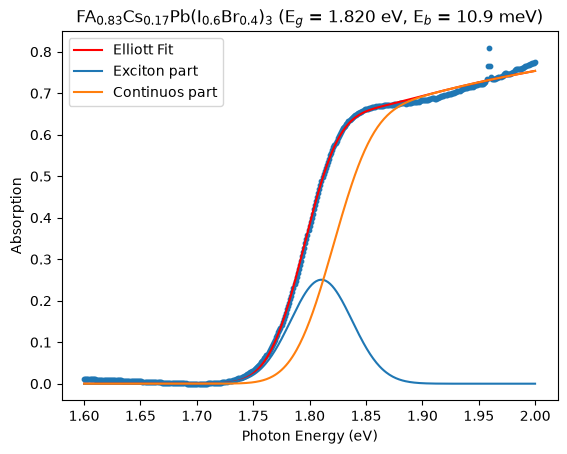

1.8389520179104335 1.8201704823733629 0.011107683470828926 0.027647881386582668


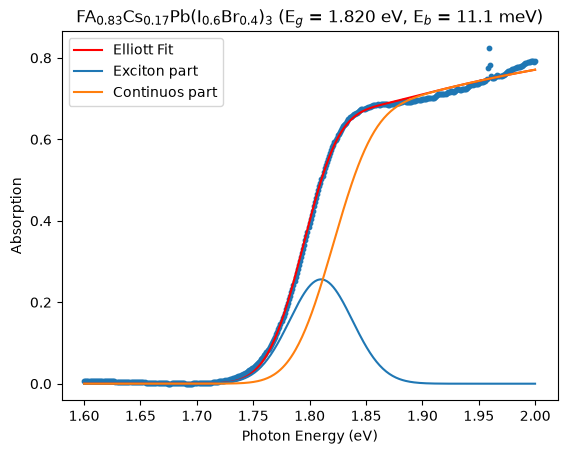

In [15]:
for key in dictionary.keys():
    #print(dictionary_plot[f"{key}_x"])
    #print(dictionary_plot[f"{key}_y"])

    x_preCut = np.asarray(dictionary_plot[f"{key}_x"])
    y_preCut = np.asarray(dictionary_plot[f"{key}_y"])

    x = []
    y = []
    for index, val in enumerate(x_preCut):
        if val < 2 and val > 1.6: #2 and 1.6
            x.append(val)
            y.append(y_preCut[index])

    x = np.array(x)
    y = np.array(y)

    ymin = np.min(y)
    y = y - ymin

    #initial guesses
    A0 = 0.0348
    #B0 = 13.0932
    EG0 = 1.
    EB0 = 10 * 10 ** -3
    sigma0 = 0.05

    p0 = [A0, EG0, EB0, sigma0]
    #bounds = ([0, 0, 1.0, 0.001, 0.001], [np.inf, np.inf, 3.0, 1.0, 1.0])

    params, covariance = curve_fit(Elliott, x, y, maxfev=100000, p0 = p0)#, bounds = bounds)

    # Uncertainties (1σ standard deviations)
    #(A_err, E_G_err, E_B_err, test_err) = np.sqrt(np.diag(covariance))
    #A, E_G, E_B, test = params
    (A_err, E_G_err, E_B_err, sigma_err) = np.sqrt(np.diag(covariance))
    A, E_G, E_B, sigma= params

    print(*params)

    plt.figure()
    plt.scatter(x, y, s=10)
    plt.plot(x, Elliott(x, *params), color="red", label="Elliott Fit")
    plt.plot(x, the_exiton_bit(x, A, E_G, E_B, sigma), label="Exciton part")
    plt.plot(x, general_bit(x, A, E_G, E_B, sigma), label="Continuos part")
    plt.title(fr"FA$_{{0.83}}$Cs$_{{0.17}}$Pb(I$_{{0.6}}$Br$_{{0.4}}$)$_{3}$ (E$_g$ = {E_G:.3f} eV, E$_b$ = {E_B*1000:.1f} meV)")
    plt.xlabel("Photon Energy (eV)")
    plt.ylabel("Absorption")
    plt.legend()
    plt.show()